# LogiTrack: Notebook 03: Exploratory Data Analysis (Step 8)
Univariate, bivariate, multivariate, trend, correlation and distribution analysis on the shipment-level feature table. Every chart is saved to `reports/figures/` for the report and presentation.

*Convention:* delay and delivery-time metrics use **completed deliveries** (Delivered + Delayed, n = 2,712). Success-rate metrics use **all shipments** (n = 3,000).

In [1]:
# --- Setup: make the project root importable and load shared helpers -------------
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

from src import utils
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline
from src.feature_engineering import WEIGHT_LABELS, DISTANCE_LABELS, EXPERIENCE_LABELS, DAY_ORDER
df = pd.read_csv(utils.CLEANED_DIR / "logitrack_master_features.csv", parse_dates=["shipment_dt", "actual_dt", "feedback_dt"])
done = df[df["is_completed"] == 1].copy()
STATUS_ORDER = ["Delivered", "Delayed", "In-Transit", "Cancelled"]
print(df.shape, done.shape)

(3000, 58) (2712, 58)


## 8.1 Univariate analysis

In [2]:
kpi = pd.Series({
    "Total shipments": len(df),
    "Completed deliveries": int(df["is_completed"].sum()),
    "Delivery success rate (status = Delivered) %": round(100 * df["is_success"].mean(), 2),
    "Completion rate (Delivered + Delayed) %": round(100 * df["is_completed"].mean(), 2),
    "Strict on-time rate (delay_hours = 0, of completed) %": round(100 * (done["delay_hours"] == 0).mean(), 2),
    "Average delay (h, completed)": round(done["delay_hours"].mean(), 2),
    "Median delay (h, completed)": round(done["delay_hours"].median(), 2),
    "Average customer rating": round(df["customer_rating"].mean(), 3),
    "Average transit time (days)": round(done["delivery_days"].mean(), 2),
})
kpi

Total shipments                                          3000.000
Completed deliveries                                     2712.000
Delivery success rate (status = Delivered) %               74.400
Completion rate (Delivered + Delayed) %                    90.400
Strict on-time rate (delay_hours = 0, of completed) %      28.580
Average delay (h, completed)                                7.080
Median delay (h, completed)                                 3.180
Average customer rating                                     3.893
Average transit time (days)                                 1.110
dtype: float64

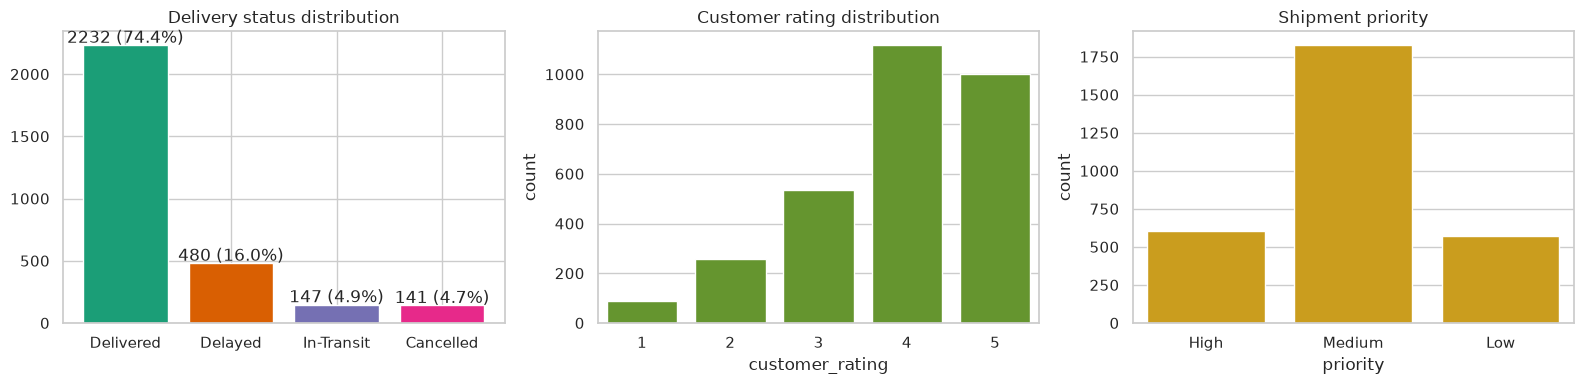

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
vc = df["delivery_status"].value_counts().reindex(STATUS_ORDER)
axes[0].bar(vc.index, vc.values, color=["#1b9e77", "#d95f02", "#7570b3", "#e7298a"])
for i, v in enumerate(vc.values): axes[0].text(i, v + 20, f"{v} ({v/len(df):.1%})", ha="center")
axes[0].set_title("Delivery status distribution")
sns.countplot(data=df, x="customer_rating", ax=axes[1], color="#66a61e").set_title("Customer rating distribution")
sns.countplot(data=df, x="priority", order=["High", "Medium", "Low"], ax=axes[2], color="#e6ab02").set_title("Shipment priority")
plt.tight_layout(); utils.save_fig(fig, "03_univariate_status_rating_priority"); plt.show()

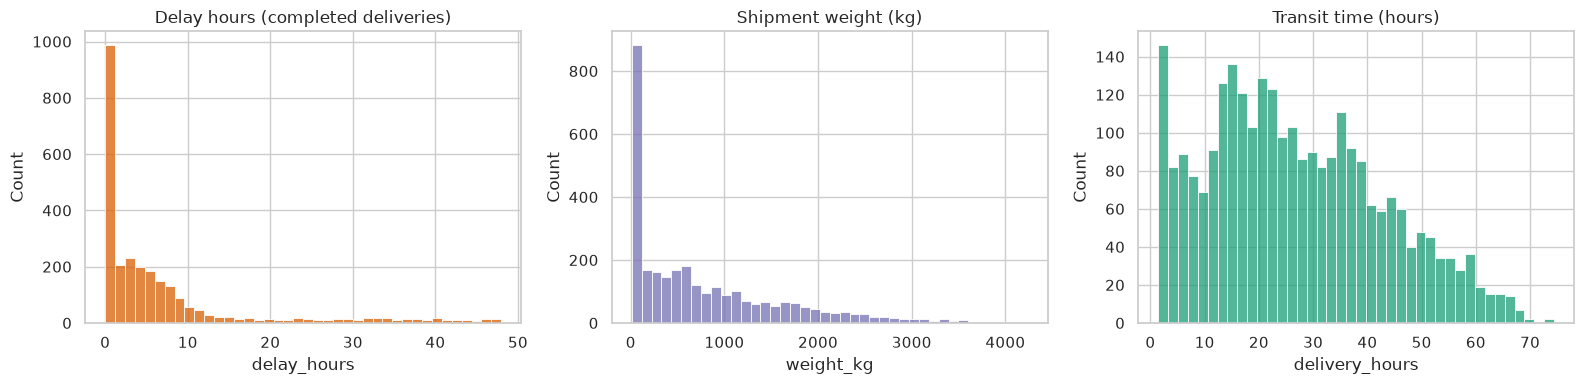

Skewness: {'delay_hours': 2.16, 'weight_kg': 1.26, 'delivery_hours': 0.43}


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(done["delay_hours"], bins=40, ax=axes[0], color="#d95f02").set_title("Delay hours (completed deliveries)")
sns.histplot(df["weight_kg"], bins=40, ax=axes[1], color="#7570b3").set_title("Shipment weight (kg)")
sns.histplot(done["delivery_hours"], bins=40, ax=axes[2], color="#1b9e77").set_title("Transit time (hours)")
plt.tight_layout(); utils.save_fig(fig, "03_univariate_distributions"); plt.show()
print("Skewness:", done[["delay_hours", "weight_kg", "delivery_hours"]].skew().round(2).to_dict())

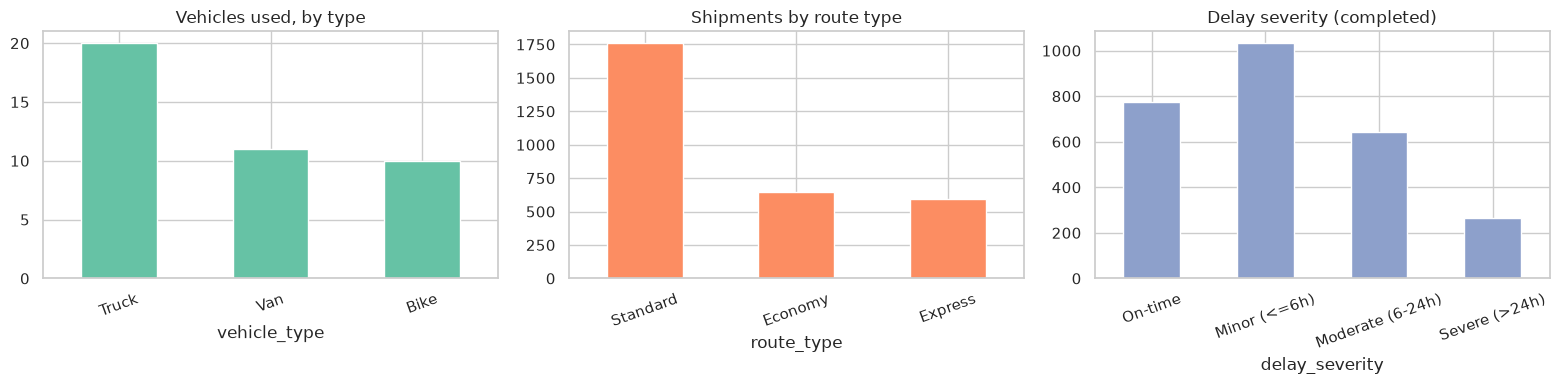

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.drop_duplicates("vehicle_id")["vehicle_type"].value_counts().plot.bar(ax=axes[0], color="#66c2a5", title="Vehicles used, by type")
df["route_type"].value_counts().plot.bar(ax=axes[1], color="#fc8d62", title="Shipments by route type")
df["delay_severity"].value_counts().reindex(["On-time", "Minor (<=6h)", "Moderate (6-24h)", "Severe (>24h)"]).plot.bar(ax=axes[2], color="#8da0cb", title="Delay severity (completed)")
for a in axes: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); utils.save_fig(fig, "03_univariate_vehicle_route_severity"); plt.show()

## 8.2 Bivariate analysis

In [6]:
# Q2: Which routes / route types have the most delays?
rt = done.groupby("route_type").agg(shipments=("shipment_id", "count"), avg_delay_h=("delay_hours", "mean"),
                                    delayed_rate=("is_delayed", "mean"), severe_rate=("delay_severity", lambda s: (s == "Severe (>24h)").mean())).round(3)
display(rt)
route = done.groupby("route_name").agg(shipments=("shipment_id", "count"), avg_delay_h=("delay_hours", "mean"),
                                       delayed_status_rate=("delivery_status", lambda s: (s == "Delayed").mean())).round(2)
print("Top 10 routes by average delay (min 15 completed shipments):")
display(route[route["shipments"] >= 15].sort_values("avg_delay_h", ascending=False).head(10))

,shipments,avg_delay_h,delayed_rate,severe_rate
route_type,,,,
Economy,571,7.325,0.708,0.103
Express,554,7.398,0.744,0.112
Standard,1587,6.879,0.706,0.089


Top 10 routes by average delay (min 15 completed shipments):


,shipments,avg_delay_h,delayed_status_rate
route_name,,,
Ahmedabad -> Delhi,23,14.09,0.39
Kolkata -> Ahmedabad,21,13.22,0.33
Delhi -> Hyderabad,15,12.79,0.47
Chennai -> Kochi,26,11.90,0.35
Jaipur -> Delhi,17,11.67,0.29
Mumbai -> Hyderabad,16,11.58,0.25
Bangalore -> Pune,22,11.48,0.27
Delhi -> Kolkata,19,11.47,0.32
Chandigarh -> Delhi,16,11.26,0.25


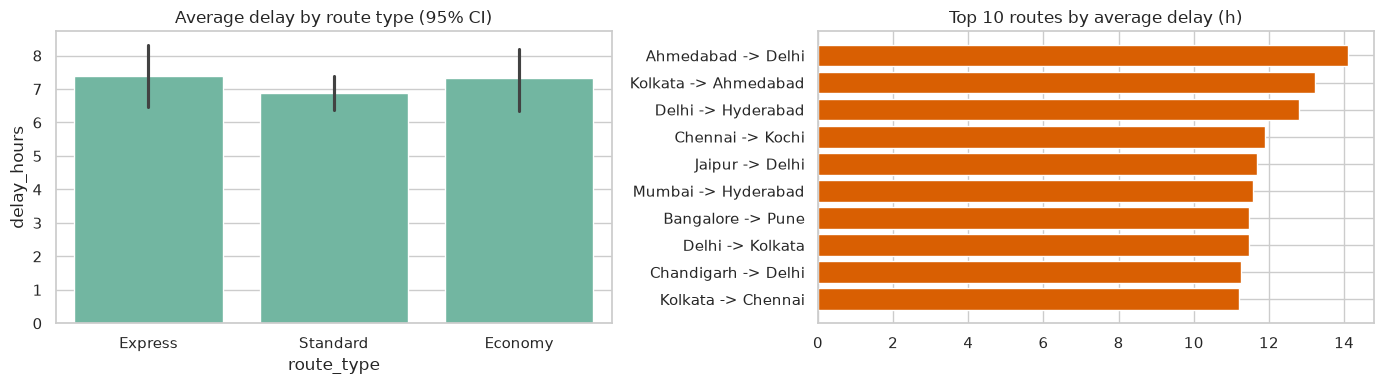

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=done, x="route_type", y="delay_hours", order=["Express", "Standard", "Economy"], ax=axes[0], errorbar=("ci", 95)).set_title("Average delay by route type (95% CI)")
top = route[route["shipments"] >= 15].sort_values("avg_delay_h", ascending=False).head(10)
axes[1].barh(top.index[::-1], top["avg_delay_h"][::-1], color="#d95f02"); axes[1].set_title("Top 10 routes by average delay (h)")
plt.tight_layout(); utils.save_fig(fig, "03_bivariate_route_delay"); plt.show()

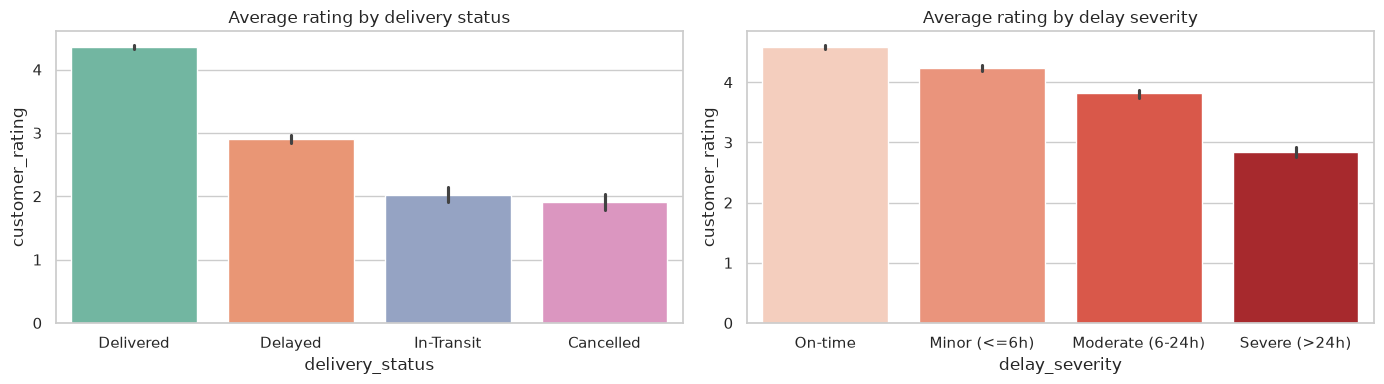

,mean,count
delivery_status,,
Delivered,4.35,2232
Delayed,2.91,480
In-Transit,2.02,147
Cancelled,1.91,141


,mean,count
delay_severity,,
On-time,4.58,775
Minor (<=6h),4.23,1033
Moderate (6-24h),3.81,641
Severe (>24h),2.84,263


In [8]:
# Q5: What drives customer satisfaction? -> rating by status and delay severity
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=df, x="delivery_status", y="customer_rating", order=STATUS_ORDER, ax=axes[0], palette="Set2").set_title("Average rating by delivery status")
sev_order = ["On-time", "Minor (<=6h)", "Moderate (6-24h)", "Severe (>24h)"]
sns.barplot(data=done, x="delay_severity", y="customer_rating", order=sev_order, ax=axes[1], palette="Reds").set_title("Average rating by delay severity")
plt.tight_layout(); utils.save_fig(fig, "03_bivariate_rating_drivers"); plt.show()
display(df.groupby("delivery_status")["customer_rating"].agg(["mean", "count"]).reindex(STATUS_ORDER).round(2))
display(done.groupby("delay_severity")["customer_rating"].agg(["mean", "count"]).reindex(sev_order).round(2))

,shipments,avg_delay_h,delayed_status_rate,avg_rating,success_rate_all
experience_level,,,,,
Junior,549,7.699,0.189,4.067,0.732
Mid,654,7.181,0.185,4.046,0.744
Senior,738,6.839,0.172,4.108,0.744
Expert,771,6.779,0.166,4.154,0.752


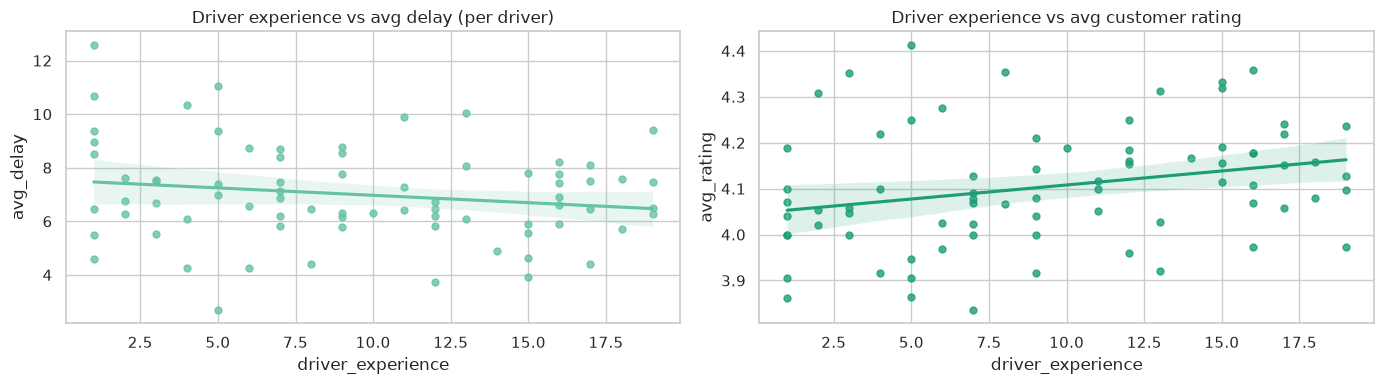

In [9]:
# Q3: Driver experience vs performance
exp = done.groupby("experience_level").agg(shipments=("shipment_id", "count"), avg_delay_h=("delay_hours", "mean"),
                                           delayed_status_rate=("delivery_status", lambda s: (s == "Delayed").mean()),
                                           avg_rating=("customer_rating", "mean")).reindex(EXPERIENCE_LABELS).round(3)
exp["success_rate_all"] = df.groupby("experience_level")["is_success"].mean().reindex(EXPERIENCE_LABELS).round(3)
display(exp)
drv = done.groupby(["driver_id", "driver_experience"]).agg(avg_delay=("delay_hours", "mean"), avg_rating=("customer_rating", "mean"), n=("shipment_id", "count")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.regplot(data=drv, x="driver_experience", y="avg_delay", ax=axes[0], scatter_kws={"s": 25}).set_title("Driver experience vs avg delay (per driver)")
sns.regplot(data=drv, x="driver_experience", y="avg_rating", ax=axes[1], scatter_kws={"s": 25}, color="#1b9e77").set_title("Driver experience vs avg customer rating")
plt.tight_layout(); utils.save_fig(fig, "03_bivariate_experience_performance"); plt.show()

,shipments,avg_delay_h,delayed_status_rate,avg_speed_kmph,avg_util_pct,avg_rating,success_rate_all,shipments_per_vehicle
vehicle_type,,,,,,,,
Bike,657,6.49,0.16,44.82,54.12,4.12,0.769,71.8
Truck,1312,7.54,0.18,45.13,45.05,4.09,0.736,73.0
Van,743,6.79,0.18,44.79,46.16,4.10,0.736,74.8


,avg_delay_h,success,n
fuel_type,,,
Diesel,6.820,0.833,1075
Electric,7.684,0.813,465
Petrol,7.076,0.817,1172


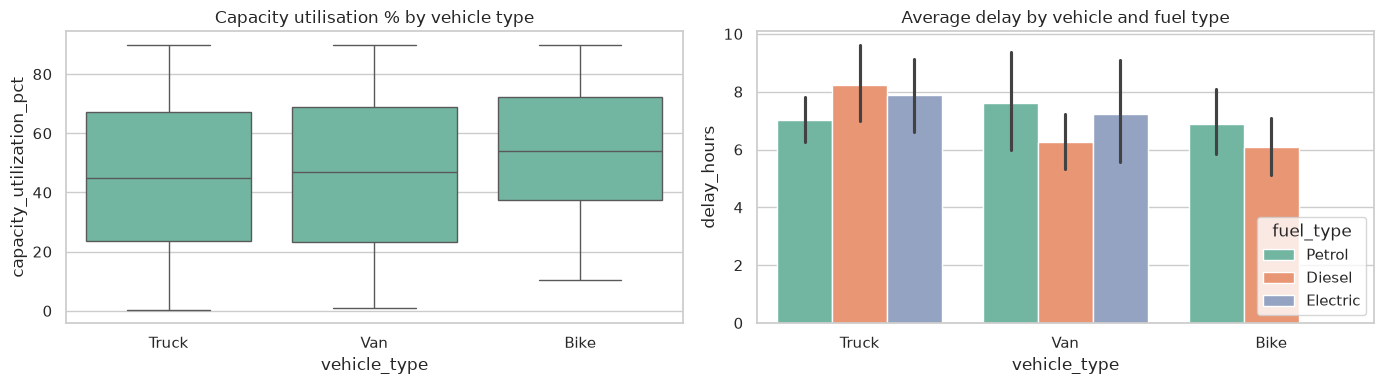

In [10]:
# Q4: Which vehicle types are most efficient?
veh = done.groupby("vehicle_type").agg(shipments=("shipment_id", "count"), avg_delay_h=("delay_hours", "mean"),
                                       delayed_status_rate=("delivery_status", lambda s: (s == "Delayed").mean()),
                                       avg_speed_kmph=("speed_kmph", "mean"), avg_util_pct=("capacity_utilization_pct", "mean"),
                                       avg_rating=("customer_rating", "mean")).round(2)
veh["success_rate_all"] = df.groupby("vehicle_type")["is_success"].mean().round(3)
veh["shipments_per_vehicle"] = (df.groupby("vehicle_type")["shipment_id"].count() / df.groupby("vehicle_type")["vehicle_id"].nunique()).round(1)
display(veh)
fuel = done.groupby("fuel_type").agg(avg_delay_h=("delay_hours", "mean"), success=("is_success", "mean"), n=("shipment_id", "count")).round(3)
display(fuel)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=done, x="vehicle_type", y="capacity_utilization_pct", ax=axes[0]).set_title("Capacity utilisation % by vehicle type")
sns.barplot(data=done, x="vehicle_type", y="delay_hours", hue="fuel_type", ax=axes[1]).set_title("Average delay by vehicle and fuel type")
plt.tight_layout(); utils.save_fig(fig, "03_bivariate_vehicle_efficiency"); plt.show()

,,shipments,success_rate,avg_rating,avg_delay_h
warehouse_name,warehouse_city,,,,
Warehouse_2,Delhi,218,0.780,4.023,6.51
Warehouse_15,Patna,194,0.778,3.804,6.13
Warehouse_10,Lucknow,166,0.777,3.880,6.32
Warehouse_11,Chandigarh,227,0.775,3.969,6.41
Warehouse_1,Mumbai,204,0.765,3.956,7.00
Warehouse_5,Chennai,196,0.755,3.949,7.62
Warehouse_3,Bangalore,195,0.754,3.867,7.17
Warehouse_13,Indore,199,0.744,3.859,6.24
Warehouse_7,Pune,201,0.741,3.975,6.56


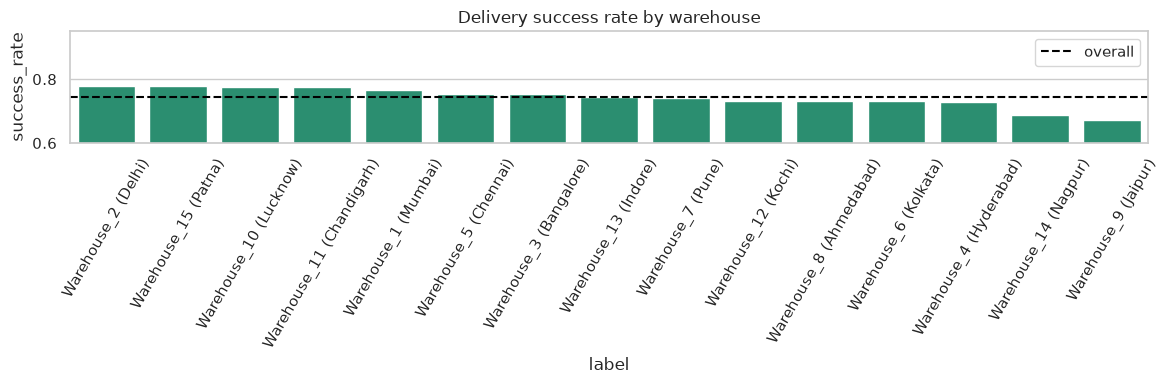

In [11]:
# Q7: Which warehouses perform best?
wh = df.groupby(["warehouse_name", "warehouse_city"]).agg(shipments=("shipment_id", "count"), success_rate=("is_success", "mean"),
                                                         avg_rating=("customer_rating", "mean")).round(3)
wh["avg_delay_h"] = done.groupby(["warehouse_name", "warehouse_city"])["delay_hours"].mean().round(2)
wh = wh.sort_values("success_rate", ascending=False)
display(wh)
fig, ax = plt.subplots(figsize=(12, 4))
w2 = wh.reset_index(); w2["label"] = w2["warehouse_name"] + " (" + w2["warehouse_city"] + ")"
sns.barplot(data=w2, x="label", y="success_rate", ax=ax, color="#1b9e77"); ax.axhline(df["is_success"].mean(), ls="--", c="k", label="overall")
ax.set_ylim(0.6, 0.95); ax.tick_params(axis="x", rotation=60); ax.legend(); ax.set_title("Delivery success rate by warehouse")
plt.tight_layout(); utils.save_fig(fig, "03_bivariate_warehouse_success"); plt.show()

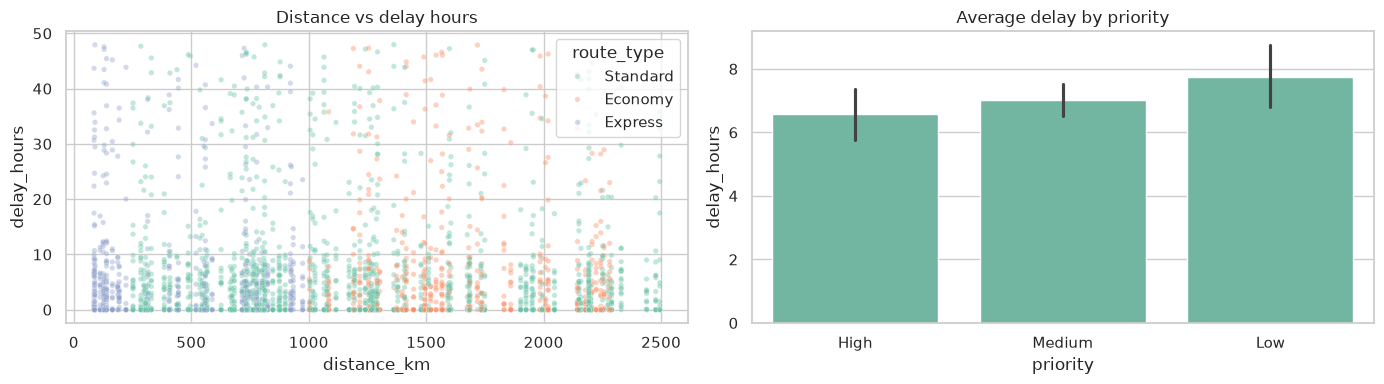

,delay_hours,is_delayed
distance_category,,
Short,7.641,0.736
Medium,6.975,0.724
Long,7.218,0.696
Very Long,6.736,0.707


,is_success,delay_hours
priority,,
High,0.749,6.59
Low,0.712,7.76
Medium,0.752,7.03


In [12]:
# Distance vs delay, and priority
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.scatterplot(data=done, x="distance_km", y="delay_hours", hue="route_type", alpha=0.4, s=15, ax=axes[0]).set_title("Distance vs delay hours")
sns.barplot(data=done, x="priority", y="delay_hours", order=["High", "Medium", "Low"], ax=axes[1]).set_title("Average delay by priority")
plt.tight_layout(); utils.save_fig(fig, "03_bivariate_distance_priority"); plt.show()
display(done.groupby("distance_category")[["delay_hours", "is_delayed"]].mean().reindex(DISTANCE_LABELS).round(3))
display(df.groupby("priority")[["is_success"]].mean().round(3).join(done.groupby("priority")[["delay_hours"]].mean().round(2)))

## 8.3 Multivariate analysis

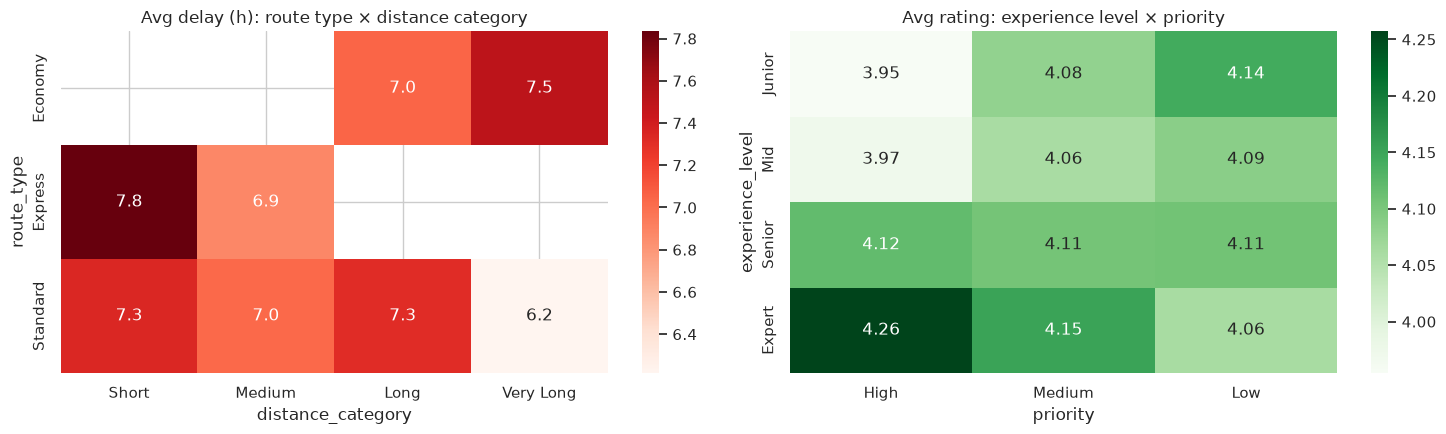

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
p1 = done.pivot_table(index="route_type", columns="distance_category", values="delay_hours", aggfunc="mean").reindex(columns=DISTANCE_LABELS)
sns.heatmap(p1, annot=True, fmt=".1f", cmap="Reds", ax=axes[0]).set_title("Avg delay (h): route type × distance category")
p2 = done.pivot_table(index="experience_level", columns="priority", values="customer_rating", aggfunc="mean").reindex(EXPERIENCE_LABELS)[["High", "Medium", "Low"]]
sns.heatmap(p2, annot=True, fmt=".2f", cmap="Greens", ax=axes[1]).set_title("Avg rating: experience level × priority")
plt.tight_layout(); utils.save_fig(fig, "03_multivariate_heatmaps"); plt.show()

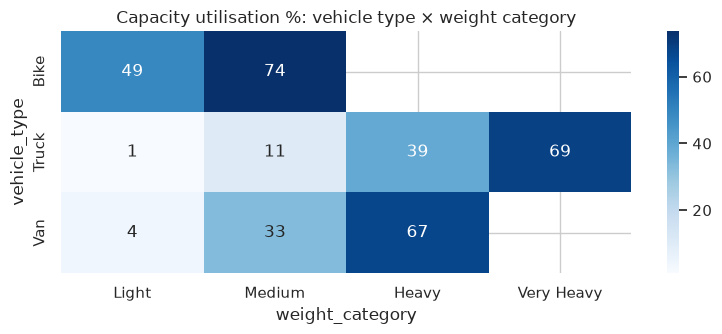

In [14]:
p3 = done.pivot_table(index="vehicle_type", columns="weight_category", values="capacity_utilization_pct", aggfunc="mean").reindex(columns=WEIGHT_LABELS)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(p3, annot=True, fmt=".0f", cmap="Blues", ax=ax).set_title("Capacity utilisation %: vehicle type × weight category")
plt.tight_layout(); utils.save_fig(fig, "03_multivariate_utilisation"); plt.show()

## 8.4 Trend analysis (seasonality)

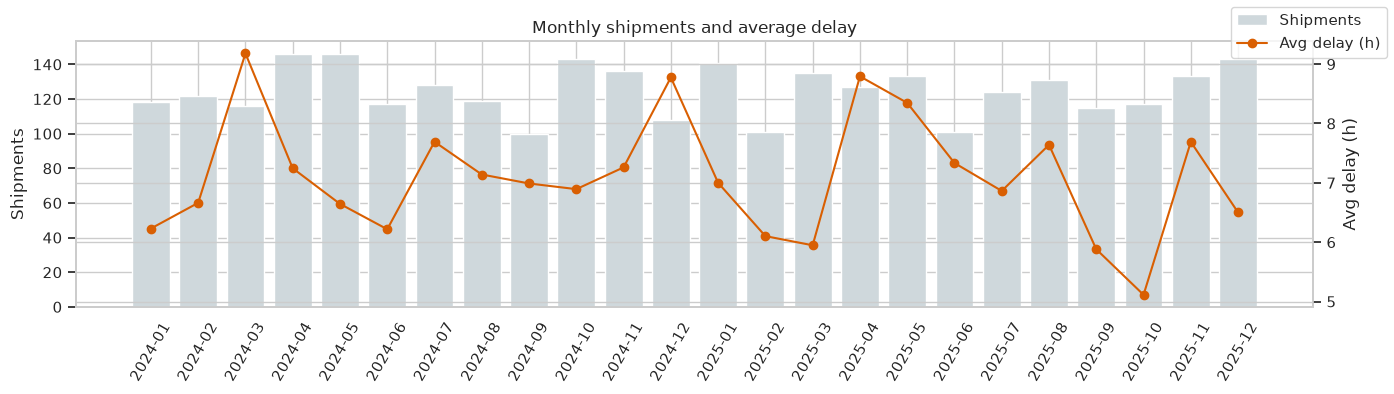

shipment_month,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
shipments,118.000,122.000,116.000,146.000,146.000,117.000,128.000,119.000,100.000,143.000,136.000,108.000,141.000,101.000,135.000,127.000,133.000,101.000,124.000,131.000,115.000,117.000,133.000,143.000
success_rate,0.746,0.713,0.647,0.760,0.808,0.744,0.734,0.739,0.770,0.734,0.779,0.630,0.723,0.802,0.815,0.772,0.677,0.713,0.742,0.748,0.817,0.812,0.677,0.741
avg_rating,3.856,3.795,3.724,3.979,4.021,3.846,3.867,3.899,3.950,3.930,3.949,3.759,3.830,4.010,3.948,3.929,3.880,3.861,3.774,3.916,3.965,4.085,3.744,3.895
avg_delay_h,6.230,6.662,9.180,7.245,6.645,6.217,7.691,7.140,6.989,6.893,7.260,8.776,7.000,6.102,5.947,8.794,8.347,7.333,6.863,7.640,5.880,5.113,7.690,6.500


In [15]:
monthly = df.groupby("shipment_month").agg(shipments=("shipment_id", "count"), success_rate=("is_success", "mean"), avg_rating=("customer_rating", "mean"))
monthly["avg_delay_h"] = done.groupby("shipment_month")["delay_hours"].mean()
fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.bar(monthly.index, monthly["shipments"], color="#cfd8dc", label="Shipments"); ax1.set_ylabel("Shipments")
ax2 = ax1.twinx(); ax2.plot(monthly.index, monthly["avg_delay_h"], "o-", c="#d95f02", label="Avg delay (h)"); ax2.set_ylabel("Avg delay (h)")
ax1.tick_params(axis="x", rotation=60); ax1.set_title("Monthly shipments and average delay"); fig.legend(loc="upper right")
plt.tight_layout(); utils.save_fig(fig, "03_trend_monthly"); plt.show()
monthly.round(3).T

month,1,2,3,4,5,6,7,8,9,10,11,12
avg_delay_h,6.648,6.401,7.372,7.973,7.439,6.730,7.292,7.401,6.388,6.081,7.468,7.463
delayed_status_rate,0.167,0.160,0.185,0.167,0.184,0.189,0.191,0.177,0.149,0.170,0.190,0.191
n,228.000,200.000,227.000,251.000,255.000,196.000,230.000,226.000,201.000,241.000,242.000,215.000


,avg_delay_h,delayed_status_rate,avg_rating
shipment_quarter,,,
Q1,6.824,0.171,4.092
Q2,7.432,0.179,4.121
Q3,7.053,0.174,4.065
Q4,6.988,0.183,4.112


shipment_day_of_week,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
avg_delay_h,8.09,7.15,6.72,7.22,6.78,6.91,6.76
n,362.00,360.00,384.00,405.00,412.00,410.00,379.00


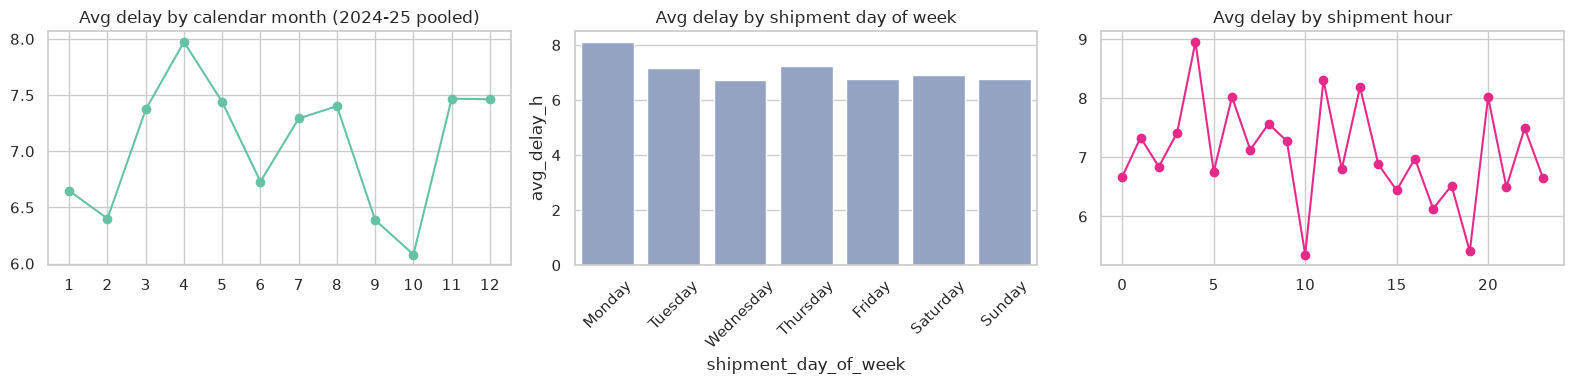

In [16]:
season = done.assign(month=done["shipment_dt"].dt.month).groupby("month").agg(avg_delay_h=("delay_hours", "mean"),
          delayed_status_rate=("delivery_status", lambda s: (s == "Delayed").mean()), n=("shipment_id", "count")).round(3)
quarter = done.groupby("shipment_quarter").agg(avg_delay_h=("delay_hours", "mean"), delayed_status_rate=("delivery_status", lambda s: (s == "Delayed").mean()), avg_rating=("customer_rating", "mean")).round(3)
dow = done.groupby("shipment_day_of_week").agg(avg_delay_h=("delay_hours", "mean"), n=("shipment_id", "count")).reindex(DAY_ORDER).round(2)
display(season.T); display(quarter); display(dow.T)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(season.index, season["avg_delay_h"], "o-"); axes[0].set_xticks(range(1, 13)); axes[0].set_title("Avg delay by calendar month (2024-25 pooled)")
sns.barplot(x=dow.index, y=dow["avg_delay_h"], ax=axes[1], color="#8da0cb"); axes[1].tick_params(axis="x", rotation=45); axes[1].set_title("Avg delay by shipment day of week")
hr = done.groupby("shipment_hour")["delay_hours"].mean()
axes[2].plot(hr.index, hr.values, "o-", c="#e7298a"); axes[2].set_title("Avg delay by shipment hour")
plt.tight_layout(); utils.save_fig(fig, "03_trend_seasonality"); plt.show()

## 8.5 Correlation analysis

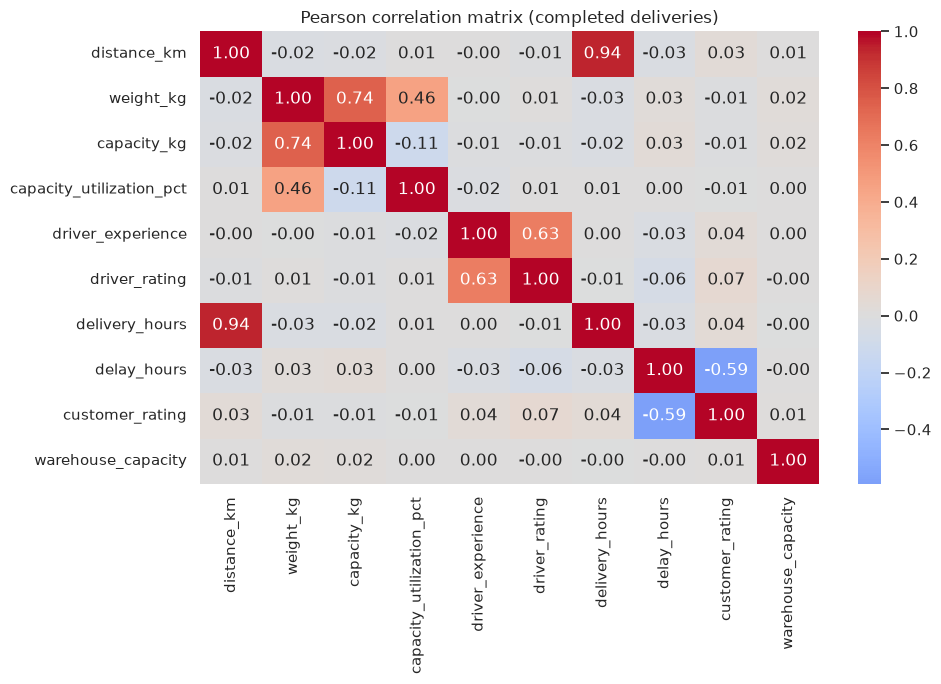

delay_hours                -0.591454
capacity_kg                -0.011066
weight_kg                  -0.007951
capacity_utilization_pct   -0.006336
warehouse_capacity          0.012271
distance_km                 0.031598
driver_experience           0.041592
delivery_hours              0.043089
driver_rating               0.065325
Name: customer_rating, dtype: float64

In [17]:
num_cols = ["distance_km", "weight_kg", "capacity_kg", "capacity_utilization_pct", "driver_experience", "driver_rating",
            "delivery_hours", "delay_hours", "customer_rating", "warehouse_capacity"]
corr = done[num_cols].corr(method="pearson")
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax).set_title("Pearson correlation matrix (completed deliveries)")
plt.tight_layout(); utils.save_fig(fig, "03_correlation_heatmap"); plt.show()
corr["customer_rating"].drop("customer_rating").sort_values()

## 8.6 Distribution analysis

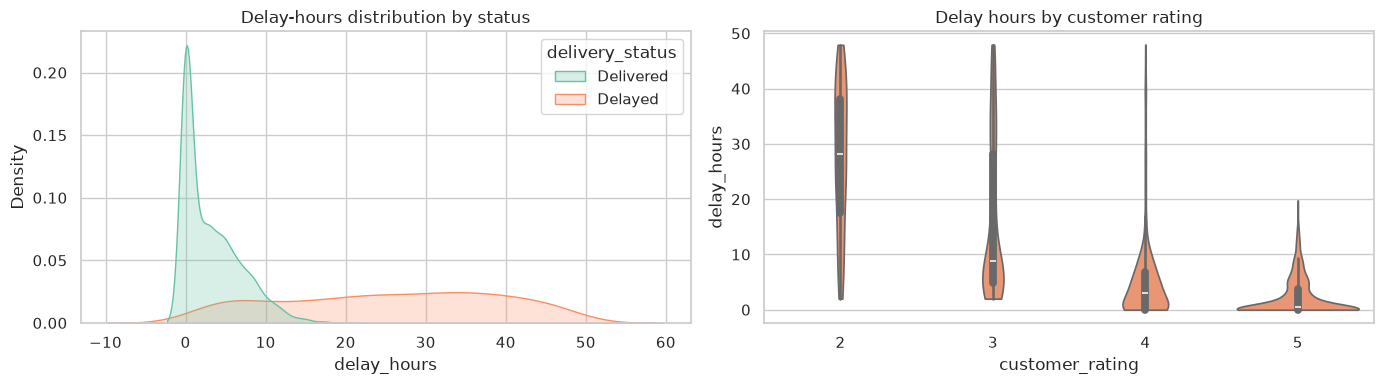

,count,mean,std,min,25%,50%,75%,max
delivery_status,,,,,,,,
Delayed,480.0,25.39,13.34,2.01,14.56,26.26,36.59,47.97
Delivered,2232.0,3.14,3.58,0.00,0.00,1.99,5.25,19.78


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(data=done, x="delay_hours", hue="delivery_status", fill=True, common_norm=False, ax=axes[0]).set_title("Delay-hours distribution by status")
sns.violinplot(data=done, x="customer_rating", y="delay_hours", ax=axes[1], color="#fc8d62", cut=0).set_title("Delay hours by customer rating")
plt.tight_layout(); utils.save_fig(fig, "03_distribution_delay"); plt.show()
done.groupby("delivery_status")["delay_hours"].describe().round(2)

In [19]:
# Comments vs rating: what do customers say?
ct = pd.crosstab(df["feedback_comment"], df["customer_rating"])
ct.loc[ct.mul(ct.columns, axis=1).sum(axis=1).div(ct.sum(axis=1)).sort_values().index]

customer_rating,1,2,3,4,5
feedback_comment,,,,,
Never again,31,0,0,0,0
Very poor,32,0,0,0,0
Terrible experience,27,0,0,0,0
Delayed delivery,0,77,0,0,0
Not satisfied,0,82,0,0,0
Poor service,0,100,0,0,0
Could be better,0,0,185,0,0
Average service,0,0,178,0,0
Okay experience,0,0,170,0,0


## EDA summary: key observations
| Business question | Observation |
|---|---|
| Q1 Success rate | **74.4%** of shipments are *Delivered*, 16.0% *Delayed*, 4.9% In-Transit and 4.7% Cancelled. 90.4% are completed, but only 28.6% of completed deliveries have zero delay. |
| Q2 Route delays | Route *type* barely matters (Express 7.4 h, Economy 7.3 h, Standard 6.9 h average delay). Specific **lanes** do: Ahmedabad→Delhi (14.1 h), Kolkata→Ahmedabad (13.2 h) and Delhi→Hyderabad (12.8 h, 47% Delayed) are the worst. |
| Q3 Experience | Delay falls steadily with experience: Junior 7.7 h, Mid 7.2 h, Senior 6.8 h, Expert 6.8 h. The Delayed-status rate falls from 18.9% to 16.6%. The effect on ratings is small (4.07 to 4.15). |
| Q4 Vehicles | **Bikes** have the lowest delay (6.5 h), the highest success (76.9%) and the highest utilisation (54%). **Trucks** have the most delay (7.5 h) and the lowest utilisation (45%). Electric vehicles show slightly higher delays (7.7 h). |
| Q5 Satisfaction | Delay is the main driver: rating falls from 4.58 (on time) to 4.23 (minor), 3.81 (moderate) and 2.84 (severe). Correlation with delay is r = −0.59. Cancelled and In-Transit orders average about 2 stars. |
| Q6 Seasonality | There is no strong seasonal cycle (quarterly delay 6.8-7.4 h). Spikes appear in **Mar-2024, Dec-2024 and Apr/May-2025** (8.8-9.2 h). Monday dispatches are the slowest (8.1 h vs about 6.8 h on other days). |
| Q7 Warehouses | Delhi (WH2, 78%), Patna (WH15), Lucknow (WH10) and Chandigarh (WH11) lead on success rate. **Jaipur (WH9, 67%, 8.3 h delay)** and **Nagpur (WH14, 69%, 8.5 h)** trail. |
| Other | Distance has no relationship with delay (r = −0.03). Priority matters a little: Low-priority orders wait longest (7.8 h vs 6.6 h for High). Feedback comments map one-to-one to rating bands, so the text adds no extra signal. |

See `reports/Business_Insights_Report.md` for Observation → Interpretation → Business Impact.

In [20]:
summary = {
    "success_rate_pct": round(100 * df["is_success"].mean(), 1),
    "delayed_status_pct": round(100 * (df["delivery_status"] == "Delayed").mean(), 1),
    "not_completed_pct": round(100 * (1 - df["is_completed"].mean()), 1),
    "avg_delay_h": round(done["delay_hours"].mean(), 2),
    "rating_on_time_vs_severe": (round(done.loc[done.delay_severity == "On-time", "customer_rating"].mean(), 2), round(done.loc[done.delay_severity == "Severe (>24h)", "customer_rating"].mean(), 2)),
    "corr_delay_rating": round(done["delay_hours"].corr(done["customer_rating"]), 3),
    "corr_distance_delay": round(done["distance_km"].corr(done["delay_hours"]), 3),
    "best_warehouse": wh.index[0], "worst_warehouse": wh.index[-1],
}
summary

{'success_rate_pct': np.float64(74.4),
 'delayed_status_pct': np.float64(16.0),
 'not_completed_pct': np.float64(9.6),
 'avg_delay_h': np.float64(7.08),
 'rating_on_time_vs_severe': (np.float64(4.58), np.float64(2.84)),
 'corr_delay_rating': np.float64(-0.591),
 'corr_distance_delay': np.float64(-0.031),
 'best_warehouse': ('Warehouse_2', 'Delhi'),
 'worst_warehouse': ('Warehouse_9', 'Jaipur')}